##Set up and paths

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import cv2
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

# EDIT: folder paths
BASE_DIR   = '/content/drive/MyDrive/DermaData'
TRAIN_ROOT = f'{BASE_DIR}/health-training-jiit'
VAL_ROOT   = f'{BASE_DIR}/health-eval-jiit'

# EDIT: set only if auto-detection in Cell 2 fails
TRAIN_CSV, VAL_CSV = None, None

CLASSES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
NC = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
IMG_EXT = ('.jpg', '.jpeg', '.png')
OUT_DIR = f'{BASE_DIR}/shared_artifacts'
os.makedirs(OUT_DIR, exist_ok=True)

Mounted at /content/drive
Mounted at /content/drive


##Check Folder Structure

In [2]:
def tree(root, max_depth=3):
    root = root.rstrip('/')
    for dp, dn, fn in os.walk(root):
        depth = dp[len(root):].count('/')
        if depth > max_depth: continue
        exts = pd.Series([os.path.splitext(f)[1].lower() for f in fn]).value_counts().to_dict()
        print('  ' * depth + os.path.basename(dp) + '/', exts if exts else '')

for r in [TRAIN_ROOT, VAL_ROOT]:
    print('=' * 60); print(r)
    tree(r) if os.path.exists(r) else print('NOT FOUND')

print('\nCSV / label files found:')
for r in [TRAIN_ROOT, VAL_ROOT]:
    for p in glob.glob(r + '/**/*.csv', recursive=True) + glob.glob(r + '/**/*.txt', recursive=True) + glob.glob(r + '/**/*.json', recursive=True):
        print(' ', p)

/content/drive/MyDrive/DermaData/health-training-jiit
health-training-jiit/ {'.md': 1, '.json': 1}
  Health/ 
    training/ {'.csv': 1}
      images/ {'.jpg': 7762}
/content/drive/MyDrive/DermaData/health-eval-jiit
health-eval-jiit/ {'.md': 1, '.json': 1}
  Health/ 
    eval/ {'.csv': 1}
      images/ {'.jpg': 1942}

CSV / label files found:
  /content/drive/MyDrive/DermaData/health-training-jiit/Health/training/metadata.csv
  /content/drive/MyDrive/DermaData/health-training-jiit/manifest.json
  /content/drive/MyDrive/DermaData/health-eval-jiit/Health/eval/metadata.csv
  /content/drive/MyDrive/DermaData/health-eval-jiit/manifest.json


##Labels Load and Verify

In [3]:
def index_images(root):
    idx, dup = {}, 0
    for p in glob.glob(os.path.join(root, '**', '*'), recursive=True):
        if p.lower().endswith(IMG_EXT):
            k = os.path.splitext(os.path.basename(p))[0]
            if k in idx: dup += 1
            idx[k] = p
    return idx, dup

def parse_label_csv(path):
    # supports one-hot columns (MEL, NV, ...) or a single label column (dx / label / class ...)
    df = pd.read_csv(path)
    low = {c.lower(): c for c in df.columns}
    id_col = next((low[c] for c in ['image_id', 'image', 'id', 'filename', 'file', 'name'] if c in low), df.columns[0])
    onehot = [c for c in df.columns if c.lower() in CLASSES]
    if len(onehot) >= 5:
        label = [c.lower() for c in np.array(onehot)[df[onehot].values.argmax(1)]]
    else:
        lab_col = next((low[c] for c in ['dx', 'label', 'labels', 'class', 'diagnosis', 'target'] if c in low), None)
        if lab_col is None: return None
        label = df[lab_col].astype(str).str.lower().str.strip().tolist()
    out = pd.DataFrame({'image_id': df[id_col].astype(str).map(lambda s: os.path.splitext(os.path.basename(s))[0]), 'label': label})
    for std, alts in {'age': ['age', 'age_approx'], 'sex': ['sex', 'gender'],
                      'localization': ['localization', 'localisation', 'loc', 'site']}.items():
        c = next((low[a] for a in alts if a in low), None)
        if c is not None: out[std] = df[c].values
    return out

def load_split(root, csv_path):
    idx, dup = index_images(root)
    lab = parse_label_csv(csv_path) if csv_path else None
    if lab is None:
        for p in glob.glob(root + '/**/*.csv', recursive=True):
            try:
                t = parse_label_csv(p)
                if t is not None and t['label'].isin(CLASSES).mean() > 0.9:
                    lab, csv_path = t, p; break
            except Exception: pass
    if lab is None:   # fallback: parent folder name = class
        lab = pd.DataFrame([(k, os.path.basename(os.path.dirname(p)).lower()) for k, p in idx.items()], columns=['image_id', 'label'])
        if lab['label'].isin(CLASSES).mean() < 0.9:
            raise RuntimeError(f'No labels found for {root}. Set TRAIN_CSV / VAL_CSV manually.')
        csv_path = 'folder names'
    lab = lab.drop_duplicates('image_id')
    lab['path'] = lab['image_id'].map(idx)
    print(f'{root}\n  labels from: {csv_path}\n  images on disk: {len(idx)} (dup names: {dup}) | label rows: {len(lab)}'
          f' | rows without image: {lab.path.isna().sum()} | images without label: {len(set(idx) - set(lab.image_id))}')
    lab = lab.dropna(subset=['path'])
    lab = lab[lab.label.isin(CLASSES)].reset_index(drop=True)
    lab['y'] = lab.label.map(CLS2IDX)
    return lab

train_df = load_split(TRAIN_ROOT, TRAIN_CSV)
val_df   = load_split(VAL_ROOT, VAL_CSV)
print('\nExpected: train 7815, val 2000 | Found:', len(train_df), len(val_df))
META_COLS = [c for c in ['age', 'sex', 'localization'] if c in train_df.columns]
print('Metadata columns:', META_COLS)
print(train_df.label.value_counts())

/content/drive/MyDrive/DermaData/health-training-jiit
  labels from: /content/drive/MyDrive/DermaData/health-training-jiit/Health/training/metadata.csv
  images on disk: 7762 (dup names: 0) | label rows: 7762 | rows without image: 0 | images without label: 0
/content/drive/MyDrive/DermaData/health-eval-jiit
  labels from: /content/drive/MyDrive/DermaData/health-eval-jiit/Health/eval/metadata.csv
  images on disk: 1942 (dup names: 0) | label rows: 1942 | rows without image: 0 | images without label: 0

Expected: train 7815, val 2000 | Found: 7762 1942
Metadata columns: ['age', 'sex', 'localization']
label
nv       5212
mel       856
bkl       848
bcc       400
akiec     249
vasc      109
df         88
Name: count, dtype: int64


##Check corrupt files and data leakage

In [4]:
def is_ok(p):
    try:
        with Image.open(p) as im: im.verify()
        return True
    except Exception: return False

with ThreadPoolExecutor(8) as ex:
    train_df['ok'] = list(tqdm(ex.map(is_ok, train_df.path), total=len(train_df), desc='train'))
    val_df['ok']   = list(tqdm(ex.map(is_ok, val_df.path),   total=len(val_df),   desc='val'))
print('Corrupt train:', (~train_df.ok).sum(), '| Corrupt val:', (~val_df.ok).sum())
train_df, val_df = train_df[train_df.ok].drop(columns='ok').reset_index(drop=True), val_df[val_df.ok].drop(columns='ok').reset_index(drop=True)

print('Train/Val overlapping IDs (leakage if > 0):', len(set(train_df.image_id) & set(val_df.image_id)))
print('Duplicate IDs inside train:', train_df.image_id.duplicated().sum())
print('Null labels:', train_df.label.isna().sum(), val_df.label.isna().sum())

train:   0%|          | 0/7762 [00:00<?, ?it/s]

val:   0%|          | 0/1942 [00:00<?, ?it/s]

Corrupt train: 0 | Corrupt val: 0
Train/Val overlapping IDs (leakage if > 0): 0
Duplicate IDs inside train: 0
Null labels: 0 0


##Check Quality features

In [5]:
def quality_features(path):
    try:
        im = cv2.imread(path)
        if im is None: return dict(corrupt=1)
        h, w = im.shape[:2]
        im = cv2.resize(im, (224, 224))
        g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY); hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
        bh = cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9)))
        return dict(corrupt=0, width=w, height=h,
                    blur=cv2.Laplacian(g, cv2.CV_64F).var(),               # low = blurry
                    brightness=g.mean(), contrast=g.std(),
                    glare=((hsv[..., 2] > 240) & (hsv[..., 1] < 40)).mean(),
                    dark_frac=(g < 20).mean(),                             # black corners / vignette
                    hair=(bh > 15).mean())                                 # hair / ruler
    except Exception:
        return dict(corrupt=1)

def add_quality(df):
    with ThreadPoolExecutor(4) as ex:
        feats = list(tqdm(ex.map(quality_features, df.path), total=len(df), desc='quality'))
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(feats)], axis=1)

train_df = add_quality(train_df); val_df = add_quality(val_df)

Q = train_df[train_df.corrupt == 0]
QT = dict(blur_low=Q.blur.quantile(0.03), bright_low=Q.brightness.quantile(0.01),
          bright_high=Q.brightness.quantile(0.995), glare_high=max(Q.glare.quantile(0.97), 0.01),
          hair_high=Q.hair.quantile(0.97), dark_high=Q.dark_frac.quantile(0.99))
print({k: round(float(v), 4) for k, v in QT.items()})

quality:   0%|          | 0/7762 [00:00<?, ?it/s]

quality:   0%|          | 0/1942 [00:00<?, ?it/s]

{'blur_low': 45.8027, 'bright_low': 113.4534, 'bright_high': 206.9716, 'glare_high': 0.0269, 'hair_high': 0.2106, 'dark_high': 0.0687}


##EDA and class distribution

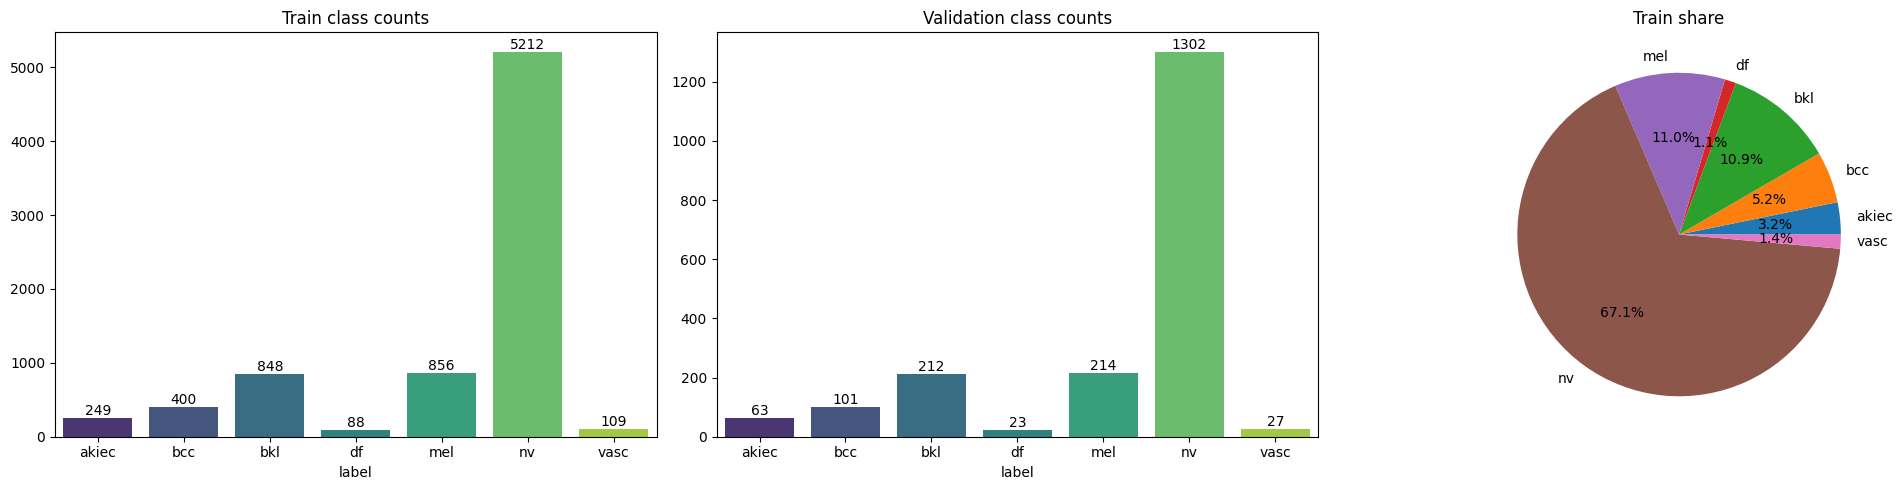

Imbalance ratio (max/min): 59.2x
Train % : {'akiec': 3.2, 'bcc': 5.2, 'bkl': 10.9, 'df': 1.1, 'mel': 11.0, 'nv': 67.1, 'vasc': 1.4}
Val   % : {'akiec': 3.2, 'bcc': 5.2, 'bkl': 10.9, 'df': 1.2, 'mel': 11.0, 'nv': 67.0, 'vasc': 1.4}


In [6]:
tc = train_df.label.value_counts().reindex(CLASSES).fillna(0)
vc = val_df.label.value_counts().reindex(CLASSES).fillna(0)

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.barplot(x=tc.index, y=tc.values, ax=ax[0], palette='viridis'); ax[0].set_title('Train class counts')
for i, v in enumerate(tc.values): ax[0].text(i, v, int(v), ha='center', va='bottom')
sns.barplot(x=vc.index, y=vc.values, ax=ax[1], palette='viridis'); ax[1].set_title('Validation class counts')
for i, v in enumerate(vc.values): ax[1].text(i, v, int(v), ha='center', va='bottom')
ax[2].pie(tc.values, labels=tc.index, autopct='%1.1f%%'); ax[2].set_title('Train share')
plt.tight_layout(); plt.show()

print(f'Imbalance ratio (max/min): {tc.max() / max(tc.min(), 1):.1f}x')
print('Train % :', (tc / tc.sum() * 100).round(1).to_dict())
print('Val   % :', (vc / vc.sum() * 100).round(1).to_dict())

##Sample images per class

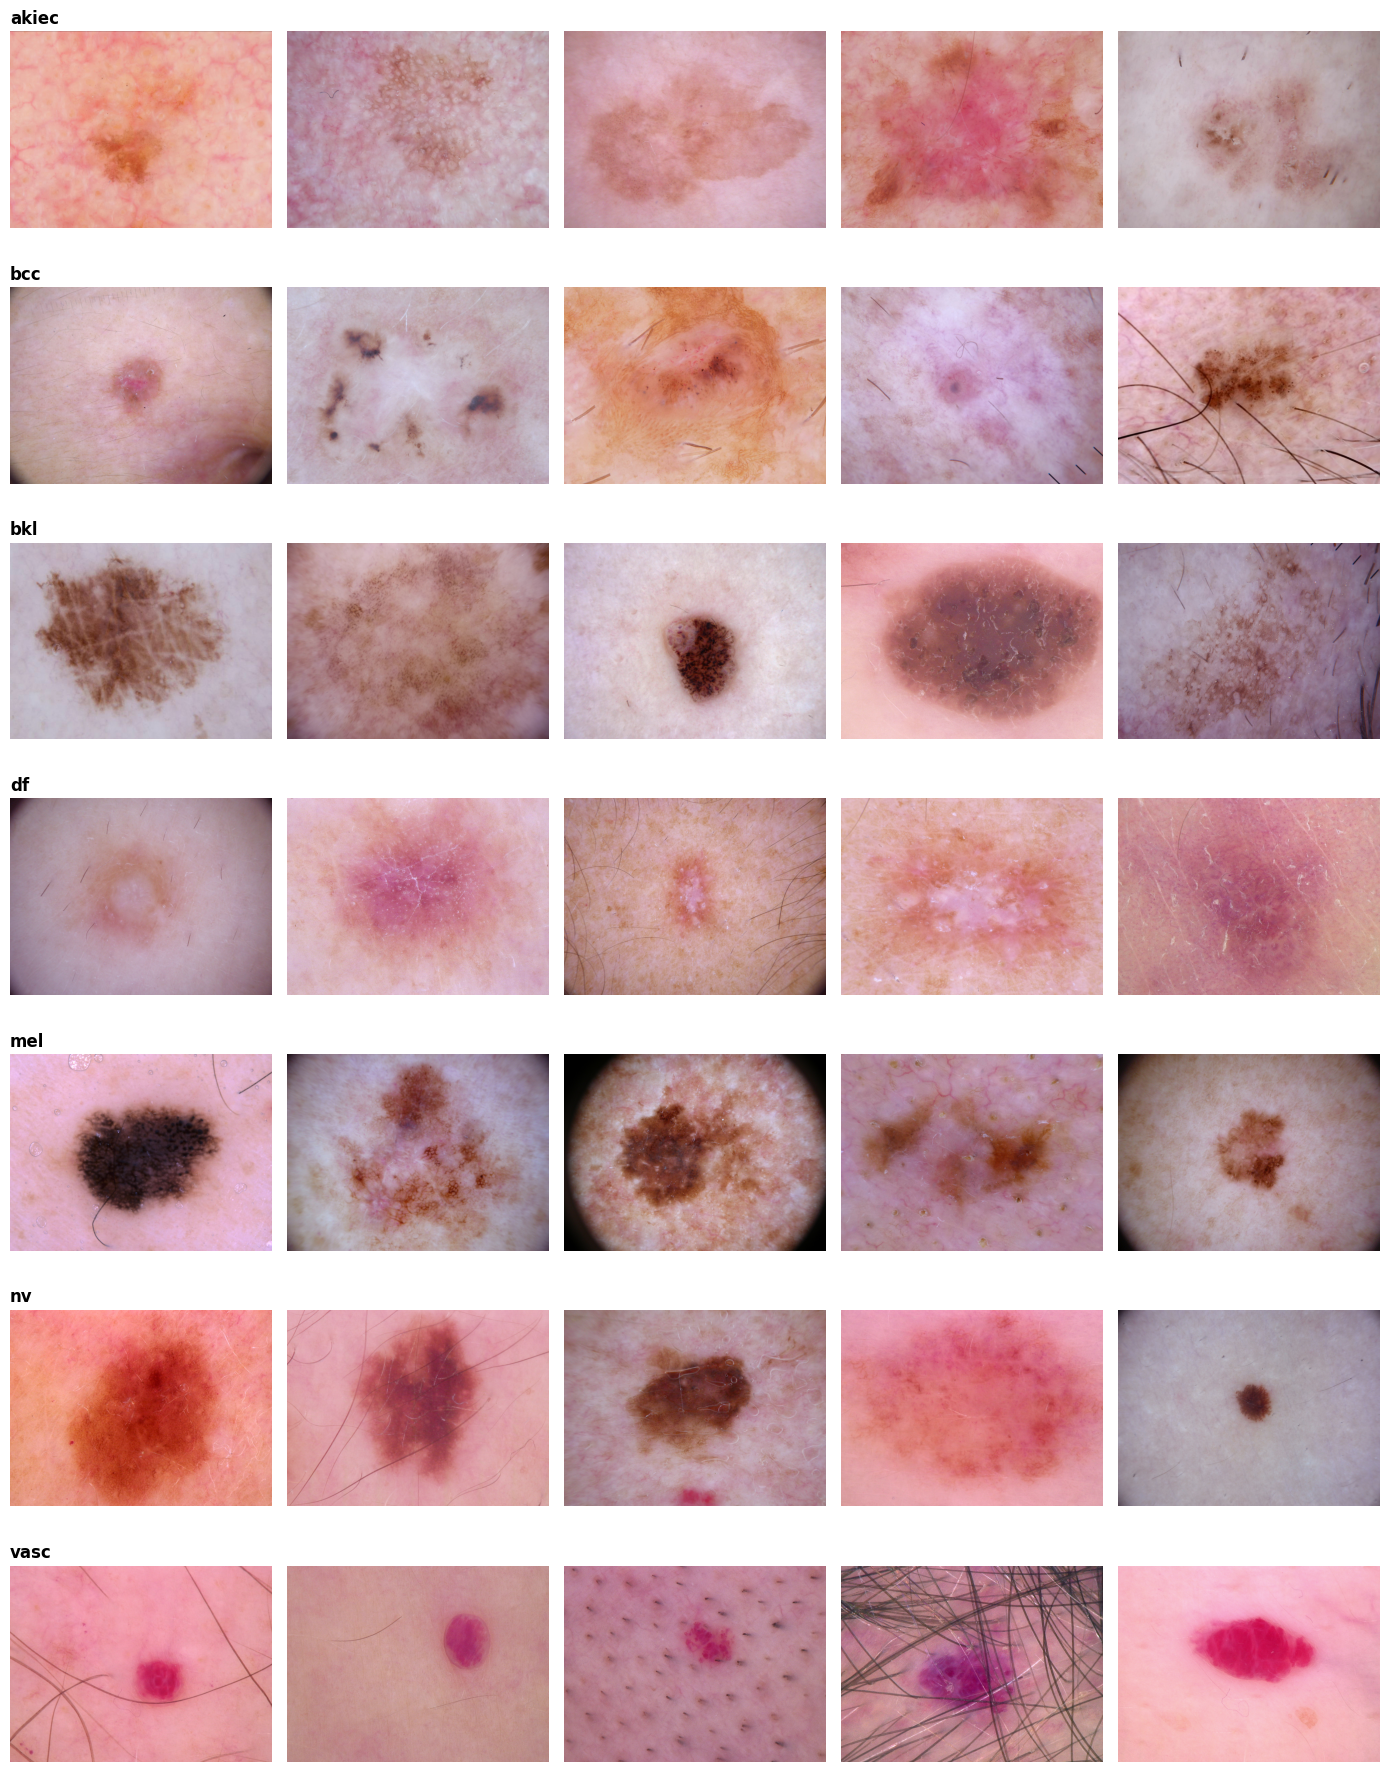

In [7]:
fig, axes = plt.subplots(NC, 5, figsize=(14, 2.6 * NC))
for r, c in enumerate(CLASSES):
    s = train_df[train_df.label == c].sample(min(5, (train_df.label == c).sum()), random_state=1)
    for k in range(5):
        axes[r, k].axis('off')
        if k < len(s):
            axes[r, k].imshow(Image.open(s.path.iloc[k]).convert('RGB'))
            if k == 0: axes[r, k].set_title(c, loc='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

##Distribution of image size and quality

Top image sizes:
width  height
600    450       7762
dtype: int64


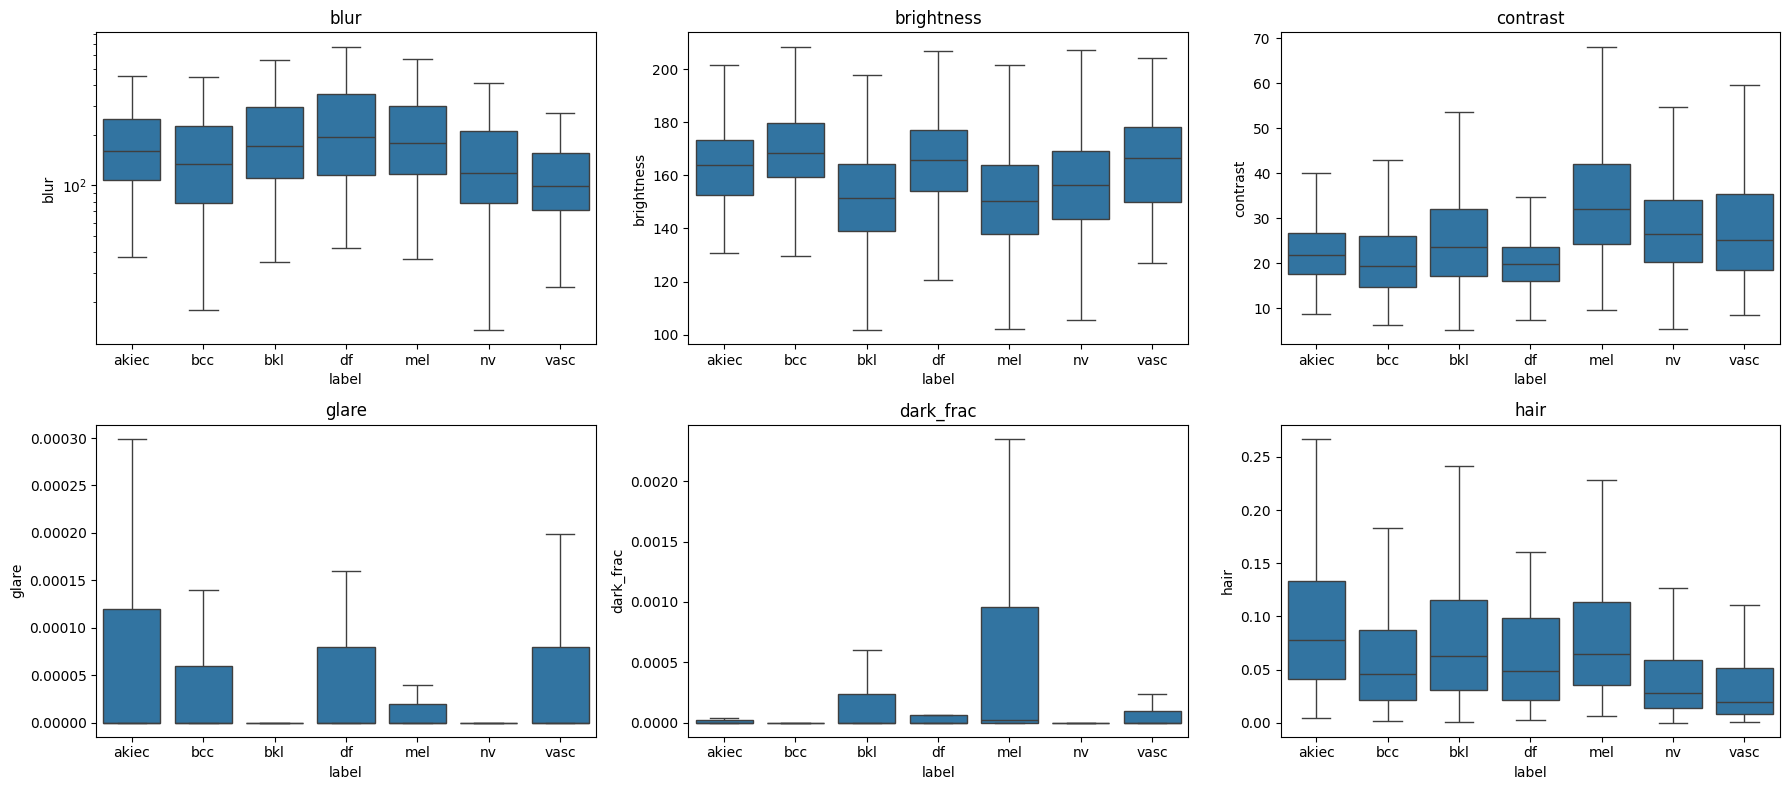

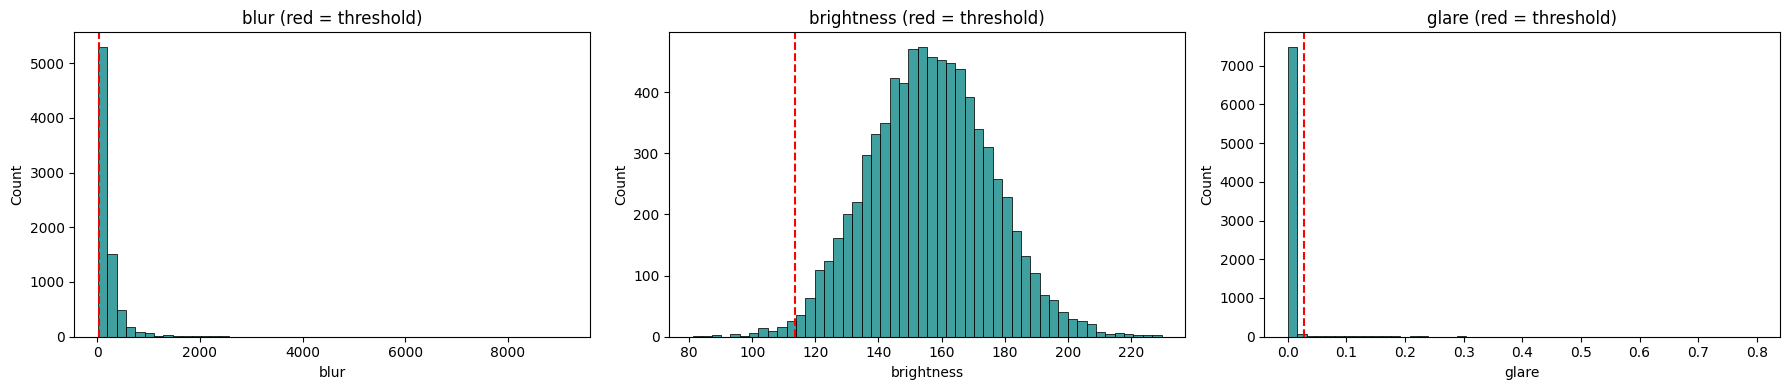

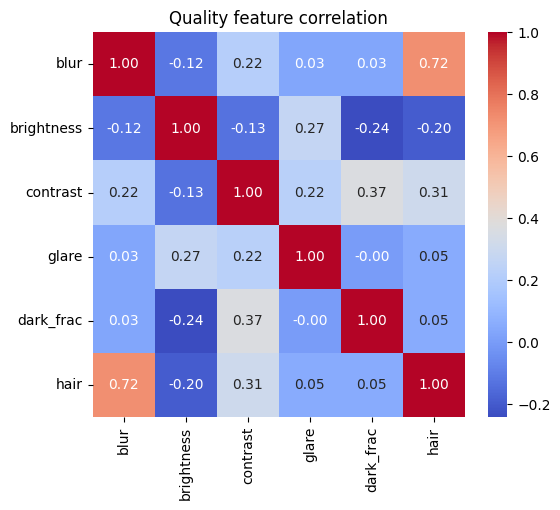

In [8]:
print('Top image sizes:'); print(train_df.groupby(['width', 'height']).size().sort_values(ascending=False).head())

feats = ['blur', 'brightness', 'contrast', 'glare', 'dark_frac', 'hair']
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, f in zip(axes.ravel(), feats):
    sns.boxplot(data=train_df, x='label', y=f, order=CLASSES, ax=a, showfliers=False); a.set_title(f)
    if f == 'blur': a.set_yscale('log')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for a, (f, k) in zip(axes, [('blur', 'blur_low'), ('brightness', 'bright_low'), ('glare', 'glare_high')]):
    sns.histplot(train_df[f], bins=50, ax=a, color='teal'); a.axvline(QT[k], color='r', ls='--'); a.set_title(f'{f} (red = threshold)')
plt.tight_layout(); plt.show()

# correlation between quality features
plt.figure(figsize=(6, 5)); sns.heatmap(train_df[feats].corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.title('Quality feature correlation'); plt.show()

##Metadata EDA and cleaning summary

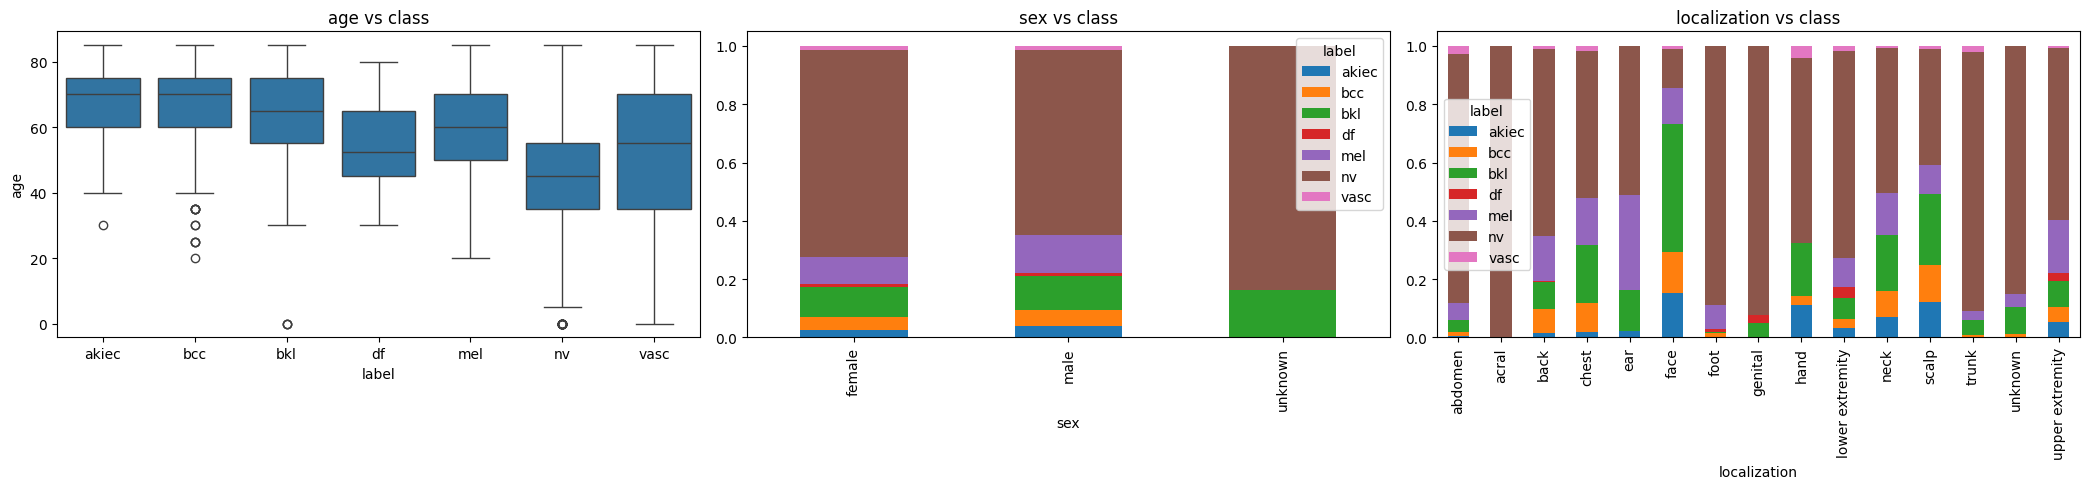

Missing %:
age             0.55
sex             0.00
localization    0.00
dtype: float64

Poor-quality train images: 347 (4.5%)
label
nv       277
bcc       28
mel       22
bkl       10
vasc       6
akiec      3
df         1
Name: count, dtype: int64


In [9]:
if META_COLS:
    fig, axes = plt.subplots(1, len(META_COLS), figsize=(7 * len(META_COLS), 5)); axes = np.atleast_1d(axes)
    for a, m in zip(axes, META_COLS):
        if m == 'age': sns.boxplot(data=train_df, x='label', y='age', order=CLASSES, ax=a)
        else: pd.crosstab(train_df[m], train_df.label, normalize='index').plot(kind='bar', stacked=True, ax=a)
        a.set_title(f'{m} vs class')
    plt.tight_layout(); plt.show()
    print('Missing %:'); print((train_df[META_COLS].isna().mean() * 100).round(2))
else:
    print('No metadata in CSV -> Context agent will treat age/sex/location as missing.')

flag = (train_df.blur < QT['blur_low']) | (train_df.brightness < QT['bright_low']) | (train_df.brightness > QT['bright_high'])
print(f'\nPoor-quality train images: {flag.sum()} ({flag.mean() * 100:.1f}%)')
print(train_df[flag].label.value_counts())
# Decision: keep them in training (model learns robustness); the Quality Agent will route similar test images to RE_IMAGE.

In [10]:
cols = ['image_id', 'path', 'label', 'y'] + META_COLS + ['width', 'height', 'blur', 'brightness', 'contrast', 'glare', 'dark_frac', 'hair', 'corrupt']
train_df[cols].to_csv(f'{OUT_DIR}/train_clean.csv', index=False)
val_df[cols].to_csv(f'{OUT_DIR}/val_clean.csv', index=False)

cnt = train_df.y.value_counts().reindex(range(NC)).fillna(1).values
cw = (cnt.sum() / (NC * cnt)) ** 0.5; cw = cw / cw.mean()
json.dump(dict(classes=CLASSES, class_weights=cw.tolist(), quality_thresholds={k: float(v) for k, v in QT.items()},
               n_train=len(train_df), n_val=len(val_df), meta_cols=META_COLS),
          open(f'{OUT_DIR}/dataset_info.json', 'w'), indent=2)
print('Saved to', OUT_DIR); print(os.listdir(OUT_DIR))

Saved to /content/drive/MyDrive/DermaData/shared_artifacts
['train_clean.csv', 'val_clean.csv', 'dataset_info.json']


In [11]:
git clone https://github.com/ba4351127-code/Agentic-DermaGuard.git
cd Agentic-DermaGuard

SyntaxError: invalid syntax (2101884355.py, line 1)